In [3]:
import pandas as pd
import torch
from torch import nn

In [29]:
dataset= pd.read_csv('ai_writing_detection_dataset.csv')
dataset = dataset.drop(columns=['Student_ID'])

# 2. Binary Encode Primary Language
dataset['Primary_Language'] = dataset['Primary_Language'].map({'Native': 1, 'Non_Native': 0})

# 3. Ordinal Encode Academic Level
level_mapping = {'High_School': 0, 'Undergraduate': 1, 'Postgraduate': 2}
dataset['Academic_Level'] = dataset['Academic_Level'].map(level_mapping)

# 4. One-Hot Encode Submission Type & Font Family
# get_dummies automatically turns categories into 1s and 0s.
# drop_first=True prevents the "dummy variable trap" (collinearity)
dataset = pd.get_dummies(dataset, columns=['Submission_Type', 'Font_Family'], drop_first=True, dtype=float)

# 1. Fill logical zeros
dataset['Citation_Count'] = dataset['Citation_Count'].fillna(0)
dataset['Plagiarism_Score'] = dataset['Plagiarism_Score'].fillna(0)

# (Assuming you agree with the copy-paste theory for AI)
dataset['Revision_Count'] = dataset['Revision_Count'].fillna(0)
dataset['Editing_Time'] = dataset['Editing_Time'].fillna(0)

# 2. Fill physical limitations with Median
median_typing = dataset['Typing_Speed'].median()
dataset['Typing_Speed'] = dataset['Typing_Speed'].fillna(median_typing)

# 1. Grab everything EXCEPT the target column for features
features_array = dataset.drop(columns=['Is_AI_Assisted']).to_numpy()
features = torch.tensor(features_array, dtype=torch.float32)

# 2. Grab EXACTLY the target column for the labels
target_array = dataset['Is_AI_Assisted'].to_numpy()
target = torch.tensor(target_array, dtype=torch.float32)

dataset.head(10)



,Academic_Level,Primary_Language,Word_Count,Average_Sentence_Length,Grammar_Errors,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Editing_Time,Revision_Count,...,Punctuation_Density,Sentence_Complexity,Submission_Hour,Is_AI_Assisted,Submission_Type_Lab_Report,Submission_Type_Literature_Review,Submission_Type_Research_Paper,Font_Family_Calibri,Font_Family_Helvetica,Font_Family_Times New Roman
0,2,1,1552,16.90,8,0.62,0.11,11.85,129.05,16.0,...,0.08,2.01,18,0,1.0,0.0,0.0,0.0,0.0,0.0
1,1,1,950,16.71,5,0.47,0.31,10.34,236.60,23.0,...,0.07,1.72,15,0,0.0,0.0,1.0,0.0,1.0,0.0
2,1,0,1103,22.10,1,0.76,0.38,14.35,4.72,4.0,...,0.08,2.35,17,1,0.0,0.0,0.0,0.0,0.0,0.0
3,2,1,1189,20.00,7,0.61,0.26,10.93,0.00,24.0,...,0.05,1.68,5,0,0.0,0.0,0.0,0.0,0.0,1.0
4,1,1,1035,22.67,2,0.80,0.33,15.30,16.82,2.0,...,0.09,2.90,8,1,0.0,0.0,0.0,0.0,1.0,0.0
5,1,0,1454,15.71,6,0.63,0.33,11.12,256.26,26.0,...,0.06,1.00,2,0,1.0,0.0,0.0,0.0,1.0,0.0
6,1,1,694,5.00,4,0.49,0.15,9.00,0.00,22.0,...,0.05,2.02,22,0,1.0,0.0,0.0,0.0,1.0,0.0
7,0,0,1980,15.23,14,0.43,0.25,9.49,0.00,21.0,...,0.08,2.36,2,0,0.0,0.0,1.0,0.0,0.0,1.0
8,2,1,1312,20.41,10,0.63,0.09,14.21,189.32,21.0,...,0.09,1.63,11,0,1.0,0.0,0.0,1.0,0.0,0.0
9,0,1,300,20.35,4,0.60,0.19,10.85,97.60,0.0,...,0.04,1.89,3,0,0.0,0.0,0.0,0.0,1.0,0.0


In [5]:
model = nn.Sequential(
    nn.Linear(22,64),
    nn.ReLU(),
    nn.Linear(64,128),
    nn.ReLU(),
    nn.Linear(128,1)
)

model.state_dict()

OrderedDict([('0.weight',
              tensor([[-0.0068, -0.1451, -0.0508,  ...,  0.0348, -0.2126, -0.1292],
                      [-0.2053, -0.0462, -0.0607,  ...,  0.1753,  0.0068, -0.0297],
                      [ 0.1535, -0.1664,  0.1477,  ..., -0.2044, -0.0609, -0.0044],
                      ...,
                      [-0.1598,  0.1542,  0.1632,  ..., -0.0415, -0.1724, -0.1592],
                      [ 0.1109,  0.0750,  0.1148,  ...,  0.2128, -0.0874, -0.1042],
                      [ 0.1307, -0.1855, -0.0608,  ...,  0.2001, -0.0868, -0.1076]])),
             ('0.bias',
              tensor([ 0.0554,  0.1994,  0.0400,  0.0404,  0.0238,  0.0063,  0.0436,  0.1127,
                       0.1856, -0.0659,  0.0849,  0.1775, -0.0920,  0.0859, -0.0421,  0.1047,
                       0.2034, -0.1674, -0.1163, -0.1526,  0.0164,  0.0782, -0.1503,  0.1921,
                      -0.0048, -0.1277,  0.1898, -0.1245, -0.0677,  0.1790,  0.1380,  0.1215,
                       0.2025, -0.1754, 

In [6]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(features,target,test_size=0.2)

def accuracy_fn(y_true,y_preds):
    correct = torch.eq(y_preds,y_true).sum().item()
    acc = correct/len(y_preds)* 100
    return acc
x_train.shape,y_train.shape

(torch.Size([8160, 22]), torch.Size([8160]))

In [7]:
loss_fn = nn.BCEWithLogitsLoss()
optimiser = torch.optim.Adam(params=model.parameters(), lr= 0.01)

In [28]:
dataset.head(10)

,Word_Count,Average_Sentence_Length,Grammar_Errors,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Editing_Time,Revision_Count,Typing_Speed,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Submission_Hour,Is_AI_Assisted
0,1552,16.90,8,0.62,0.11,11.85,129.05,16.0,24.70,3.02,0.0,0.08,2.01,18,0
1,950,16.71,5,0.47,0.31,10.34,236.60,23.0,38.84,1.71,15.0,0.07,1.72,15,0
2,1103,22.10,1,0.76,0.38,14.35,4.72,4.0,0.00,0.41,0.0,0.08,2.35,17,1
3,1189,20.00,7,0.61,0.26,10.93,NaN,24.0,41.92,3.06,5.0,0.05,1.68,5,0
4,1035,22.67,2,0.80,0.33,15.30,16.82,2.0,0.00,2.78,1.0,0.09,2.90,8,1
5,1454,15.71,6,0.63,0.33,11.12,256.26,26.0,33.40,22.68,NaN,0.06,1.00,2,0
6,694,5.00,4,0.49,0.15,9.00,NaN,22.0,31.33,2.43,2.0,0.05,2.02,22,0
7,1980,15.23,14,0.43,0.25,9.49,NaN,21.0,64.29,3.02,NaN,0.08,2.36,2,0
8,1312,20.41,10,0.63,0.09,14.21,189.32,21.0,56.66,17.57,5.0,0.09,1.63,11,0
9,300,20.35,4,0.60,0.19,10.85,97.60,NaN,45.56,1.98,2.0,0.04,1.89,3,0


In [13]:
epochs = 1000
for epoch in range(epochs):
    model.train()
    train_logits = model(x_train)
    train_loss = loss_fn(train_logits.squeeze(),y_train)
    train_preds = torch.round(torch.sigmoid(train_logits)).squeeze()
    train_accuracy = accuracy_fn(y_train,train_preds)
    optimiser.zero_grad()
    train_loss.backward()
    optimiser.step()
    model.eval()
    with torch.inference_mode():
        test_logits = model(x_test)
        test_loss = loss_fn(test_logits.squeeze(),y_test)
        test_preds = torch.round(torch.sigmoid(test_logits)).squeeze()
        test_accuracy = accuracy_fn(y_test,test_preds)
    if epoch % 100 == 0:
        print(f'epoch:{epoch:.5f} | train loss: {train_loss:.5f} | train accuracy: {train_accuracy:.5f} | test loss: {test_loss:.5f} | test accuracy | {test_accuracy:.5f}')


epoch:0.00000 | train loss: 0.00050 | train accuracy: 99.98775 | test loss: 0.01269 | test accuracy | 99.85294
epoch:100.00000 | train loss: 0.00037 | train accuracy: 100.00000 | test loss: 0.01423 | test accuracy | 99.85294
epoch:200.00000 | train loss: 0.00034 | train accuracy: 99.98775 | test loss: 0.01289 | test accuracy | 99.90196
epoch:300.00000 | train loss: 0.00030 | train accuracy: 99.98775 | test loss: 0.01603 | test accuracy | 99.90196
epoch:400.00000 | train loss: 0.00021 | train accuracy: 99.98775 | test loss: 0.01784 | test accuracy | 99.90196
epoch:500.00000 | train loss: 0.00016 | train accuracy: 100.00000 | test loss: 0.01869 | test accuracy | 99.90196
epoch:600.00000 | train loss: 0.00014 | train accuracy: 100.00000 | test loss: 0.02050 | test accuracy | 99.85294
epoch:700.00000 | train loss: 0.00012 | train accuracy: 100.00000 | test loss: 0.02107 | test accuracy | 99.90196
epoch:800.00000 | train loss: 0.00614 | train accuracy: 99.79167 | test loss: 0.03184 | test a

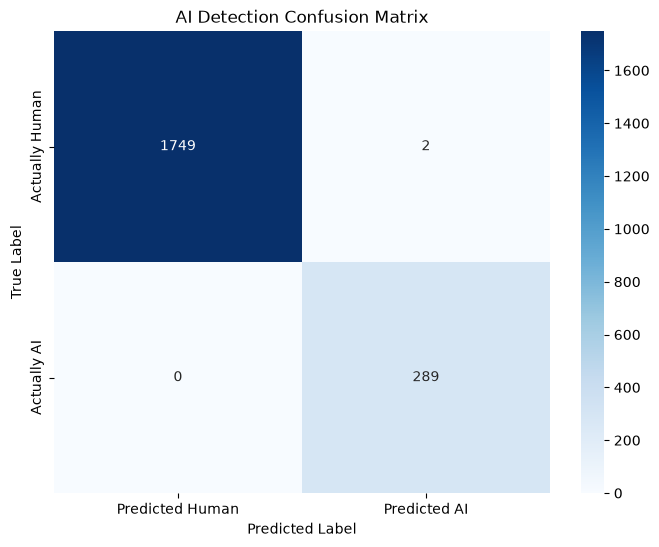

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Get the model's predictions on the test set
model.eval()
with torch.inference_mode():
    test_logits = model(x_test).squeeze()
    test_preds = torch.round(torch.sigmoid(test_logits))

# 2. Calculate the confusion matrix
# Convert tensors to numpy arrays for sklearn
cm = confusion_matrix(y_test.numpy(), test_preds.numpy())

# 3. Plot it using seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted Human', 'Predicted AI'], 
            yticklabels=['Actually Human', 'Actually AI'])
plt.title('AI Detection Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [27]:
dataset= pd.read_csv('ai_writing_detection_dataset.csv')
dataset = dataset.drop(columns=['Student_ID'])
# Drops all integer columns (both standard int64 and pandas Int64)
dataset = dataset.select_dtypes(exclude=['str'])
unique_per_col = {col: dataset[col].unique().tolist() for col in dataset.columns}
unique_per_col


{'Word_Count': [1552,
  950,
  1103,
  1189,
  1035,
  1454,
  694,
  1980,
  1312,
  300,
  757,
  938,
  738,
  1041,
  1092,
  831,
  1705,
  1870,
  1196,
  1364,
  1605,
  1463,
  1294,
  1016,
  1580,
  735,
  1308,
  1125,
  1067,
  1760,
  638,
  1703,
  602,
  922,
  1317,
  920,
  1084,
  695,
  521,
  1274,
  1512,
  1498,
  1007,
  1304,
  1248,
  1404,
  620,
  916,
  1206,
  1470,
  1204,
  1742,
  952,
  1459,
  1835,
  770,
  830,
  577,
  962,
  2094,
  1146,
  1127,
  1262,
  1622,
  1343,
  1430,
  1899,
  670,
  1268,
  1161,
  656,
  1466,
  1606,
  1561,
  1303,
  1389,
  857,
  1285,
  456,
  1246,
  1113,
  1225,
  1151,
  1401,
  980,
  707,
  1505,
  1481,
  639,
  1170,
  706,
  1531,
  1691,
  890,
  1345,
  581,
  955,
  1059,
  1275,
  1315,
  1536,
  1405,
  942,
  1379,
  1402,
  1529,
  357,
  1327,
  1539,
  1131,
  775,
  1163,
  1660,
  679,
  968,
  797,
  1100,
  611,
  1292,
  768,
  987,
  1486,
  813,
  1290,
  2004,
  1164,
  1192,
  1366,
  58

In [30]:
torch.save(model,"model.pth")

In [31]:
target.shape

torch.Size([10200])